# 周波数特性を測る(ボード線図)

フィルタの性質は、**周波数ごとのゲインと位相**で表せます。これを、横軸を周波数の対数にして描いたものが**ボード線図**です。[LPF](01_lpf.ipynb) と [HPF](02_hpf.ipynb) の模式図も、ボード線図のゲインの部分でした。

この回では、周波数を少しずつ変えながら正弦波を入れて、実際にボード線図を測ります。最後に、高い周波数で位相がずれてくる原因(遅れ)を測ります。

## 測り方

1. 信号発生器から周波数 $f$ の正弦波を出す。
2. 入力(CH1)と出力(CH2)を、数周期ぶん取り込む。
3. どちらにも周波数 $f$ の正弦波を当てはめて(`fit_sine`)、振幅と位相を求める。
4. ゲイン = 出力の振幅 / 入力の振幅、位相 = 出力の位相 − 入力の位相。
5. $f$ を変えて繰り返し、周波数ごとのゲインと位相を並べる。

**デシベル(dB)**:ゲインを $20 \log_{10} G$ で表したものです。1 倍が 0 dB、1/√2 倍が −3 dB、1/10 倍が −20 dB です。周波数を 10 倍にすることを **1 デケード(decade)** といい、1 次のフィルタの傾きは 20 dB/decade です。

取り込みは 20 kHz なので、測るのは 2 kHz 程度まで(1 周期に 10 点以上)にします。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.1, mimic=20261125)

In [2]:
import time
from mimiclab import Monitor, Response, plot_waveforms, match_phase

FC = 100                                      # cutoff frequency [Hz]
freqs = np.logspace(1, np.log10(2000), 16)    # 10 Hz - 2 kHz, 16 points
f_th = np.logspace(1, np.log10(2000), 200)    # for the theory curves


def bode_axes(title):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.set_title(title)
    ax1.set_ylabel("Gain [dB]")
    ax2.set_ylabel("Phase [deg]")
    ax2.set_xlabel("Frequency [Hz]")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.4)
    return fig, ax1, ax2

## 実験 1:LPF のボード線図を、手順どおりに測る

Mimic を $f_c$ = 100 Hz の LPF にして、上の手順をそのまま書いて測ります。まず手順 1・2 で、周波数を変えながら波形を取り込みます(各周波数で 5 周期以上、2000 点まで)。測っている最中の波形は、モニター(オシロの画面の代わり)に表示されます。

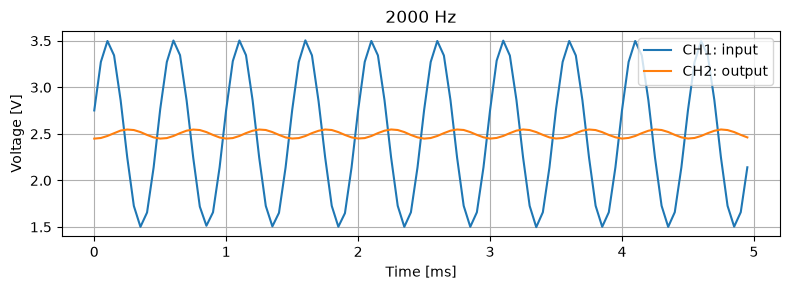

In [3]:
lab.mimic.filter1st_lpf(FC)
mon = Monitor()                                          # the screen of the oscilloscope
waves = []
for f in freqs:
    lab.fg.sine(f, 1.0)                                  # 1. sine of frequency f
    time.sleep(0.3)                                      #    wait for the filter to settle
    divider = max(1, int(np.ceil(5 / f * 20000 / 2000)))
    fs = 20000 / divider
    points = min(2000, max(100, int(np.ceil(5 / f * fs))))
    t, ch1, ch2 = lab.scope.capture(points, fs=fs)       # 2. capture 5 periods or more
    waves.append((t, ch1, ch2))
    mon.update(f, t, ch1, ch2)
mon.close()

モニターに次々に表示された波形を、周波数ごとに並べます。周波数が上がるほど、出力(CH2)が小さく、遅れていくのがわかります。

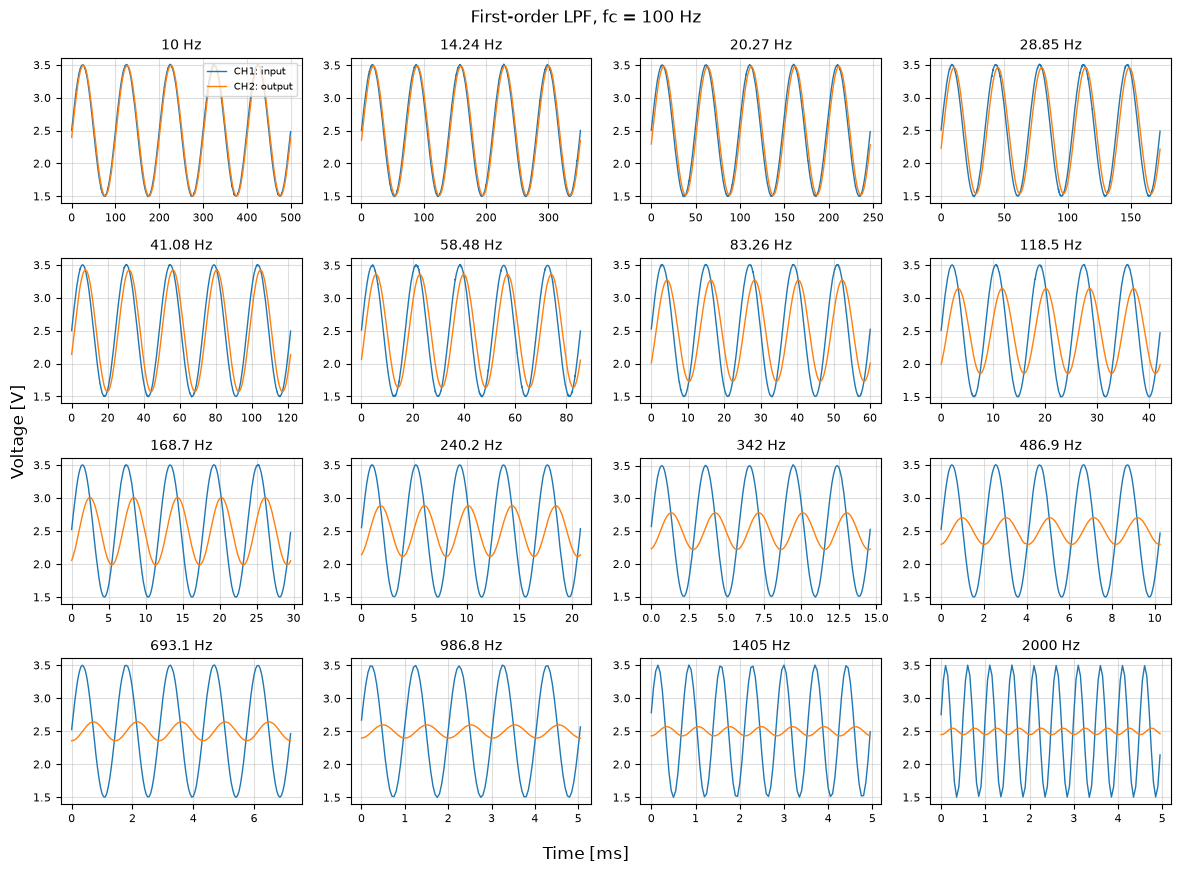

In [4]:
plot_waveforms(Response(freqs, None, None, waves), title=f"First-order LPF, fc = {FC} Hz")
plt.show()

手順 3・4 です。各周波数の入力と出力に、その周波数の正弦波を当てはめて(`fit_sine`)、振幅と位相を求めます。ゲイン = 出力の振幅 / 入力の振幅、位相 = 出力の位相 − 入力の位相です。求めた値を表にします。

In [5]:
gains, phases = [], []
for f, (t, ch1, ch2) in zip(freqs, waves):
    a1, p1, _ = fit_sine(t, ch1, f)                      # 3. fit sines
    a2, p2, _ = fit_sine(t, ch2, f)
    gains.append(a2 / a1)                                # 4. gain and phase
    phases.append((p2 - p1 + 180) % 360 - 180)
lpf = Response(freqs, np.array(gains), np.array(phases), waves)

print(" freq [Hz]   gain   gain [dB]  phase [deg]")
for f, g, p in zip(lpf.freq, lpf.gain, lpf.phase):
    print(f"{f:9.1f}  {g:6.3f}  {20 * np.log10(g):8.1f}  {p:9.1f}")

 freq [Hz]   gain   gain [dB]  phase [deg]
     10.0   0.995      -0.0       -5.8
     14.2   0.990      -0.1       -8.3
     20.3   0.980      -0.2      -11.7
     28.9   0.961      -0.3      -16.4
     41.1   0.925      -0.7      -22.8
     58.5   0.863      -1.3      -31.0
     83.3   0.769      -2.3      -40.8
    118.5   0.645      -3.8      -51.3
    168.7   0.510      -5.9      -61.4
    240.2   0.385      -8.3      -70.4
    342.0   0.281     -11.0      -77.9
    486.9   0.201     -13.9      -84.5
    693.1   0.143     -16.9      -90.5
    986.8   0.101     -19.9      -96.5
   1404.8   0.071     -23.0     -103.4
   2000.0   0.049     -26.2     -111.9


手順 5:この表を、横軸を周波数(対数)にして描いたものがボード線図です。理論($H = 1 / (1 + j f/f_c)$)と比べます。

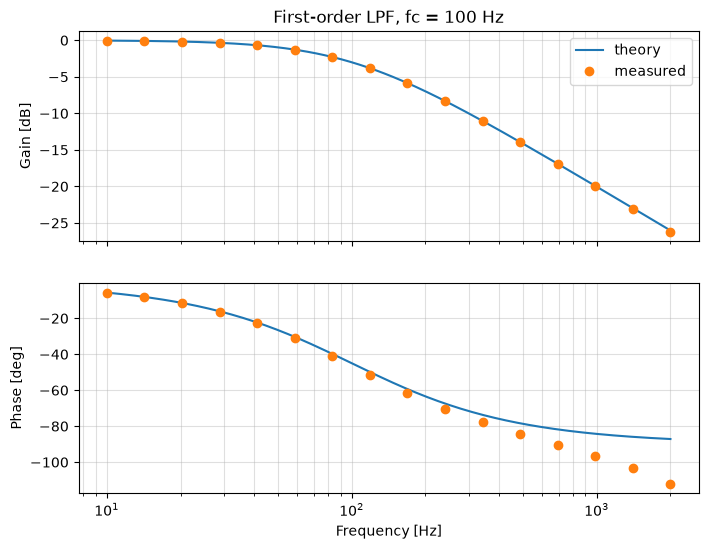

In [6]:
h = 1 / (1 + 1j * f_th / FC)
fig, ax1, ax2 = bode_axes(f"First-order LPF, fc = {FC} Hz")
ax1.semilogx(f_th, 20 * np.log10(abs(h)), "-", label="theory")
ax2.semilogx(f_th, np.degrees(np.angle(h)), "-")
ax1.semilogx(lpf.freq, lpf.gain_db, "o", label="measured")
ax2.semilogx(lpf.freq, lpf.phase, "o")
ax1.legend()
plt.show()

ゲインは理論とよく合います。位相は、周波数が高くなるほど理論より遅れていきます(実験 3 で調べます)。

## 実験 2:HPF のボード線図(`frequency_response`)

実験 1 の手順は、`lab.frequency_response(周波数の配列)` 1 行でできます。`monitor=True` にすると、実験 1 と同じように、測っている最中の波形をモニターに表示します。取り込んだ波形は、あとから `plot_waveforms` で並べて見られます。これからの講義では、この形(モニター → 波形 → ボード線図)で測ります。

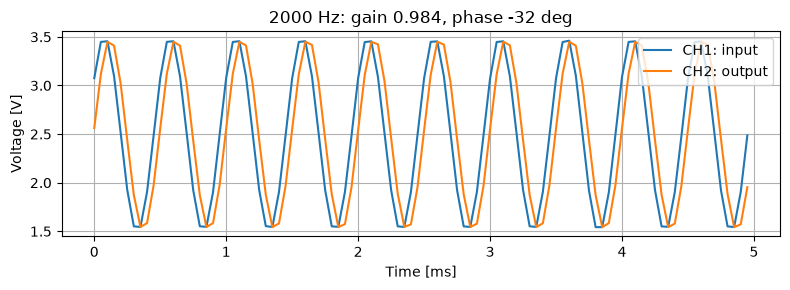

In [7]:
lab.mimic.filter1st_hpf(FC)
hpf = lab.frequency_response(freqs, monitor=True)

各周波数で取り込んだ波形です(クリックで開きます)。


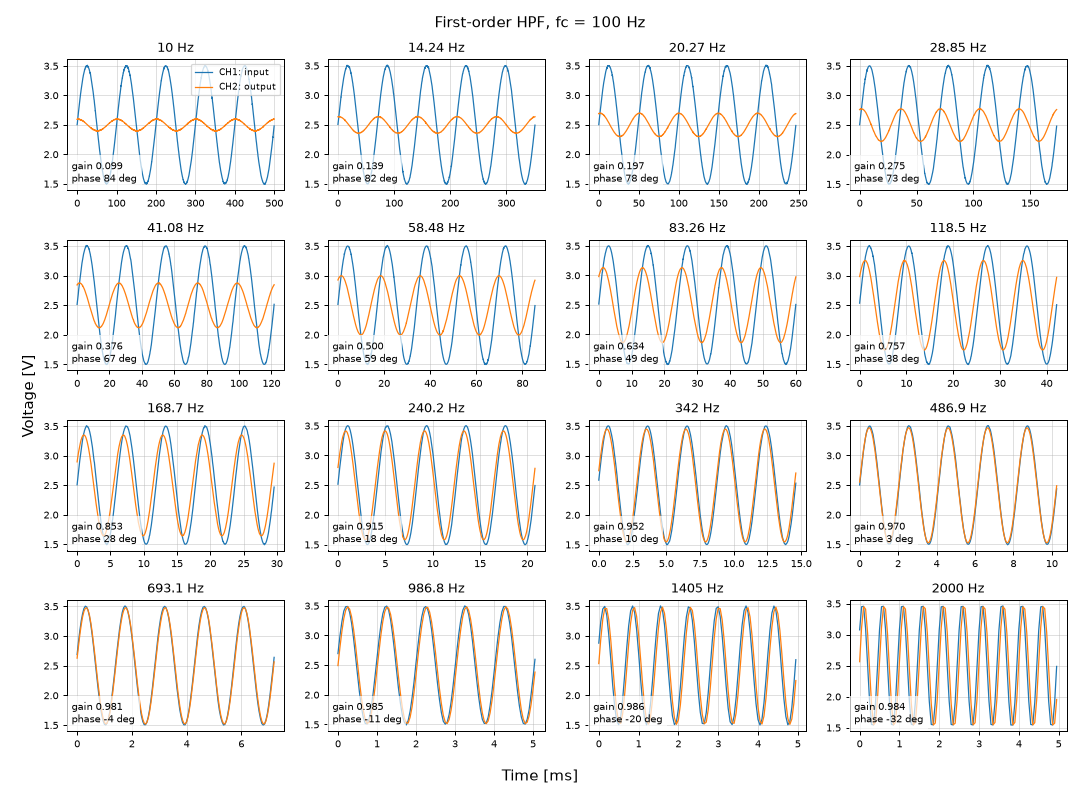

In [8]:
plot_waveforms(hpf, title=f"First-order HPF, fc = {FC} Hz", collapsed=True)

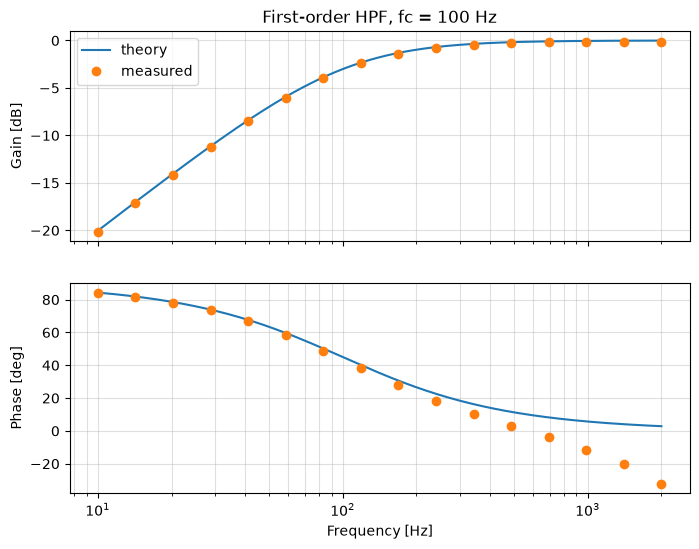

In [9]:
h = (1j * f_th / FC) / (1 + 1j * f_th / FC)
fig, ax1, ax2 = bode_axes(f"First-order HPF, fc = {FC} Hz")
ax1.semilogx(f_th, 20 * np.log10(abs(h)), "-", label="theory")
ax2.semilogx(f_th, np.degrees(np.angle(h)), "-")
ax1.semilogx(hpf.freq, hpf.gain_db, "o", label="measured")
ax2.semilogx(hpf.freq, match_phase(hpf.phase, np.degrees(np.angle((1j * hpf.freq / FC) / (1 + 1j * hpf.freq / FC)))), "o")
ax1.legend()
plt.show()

位相は 360° ずつずらしても同じ値なので、測った位相は理論に近い側にそろえて描いています(`match_phase`)。

## 実験 3:遅れを測る

位相のずれの原因を調べます。信号が一定の時間 $t_d$ だけ遅れると、周波数 $f$ の正弦波の位相は

$$\phi = -360^\circ \times f\, t_d$$

だけ遅れます。遅れの時間は同じでも、周波数が高いほど 1 周期が短いので、位相のずれは大きくなります。

Mimic をバイパス(出力 = 入力)にして位相を測り、直線を当てはめて $t_d$ を求めます。

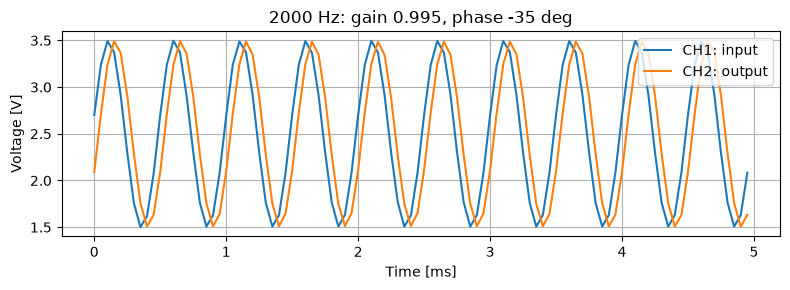

delay: 48.6 us


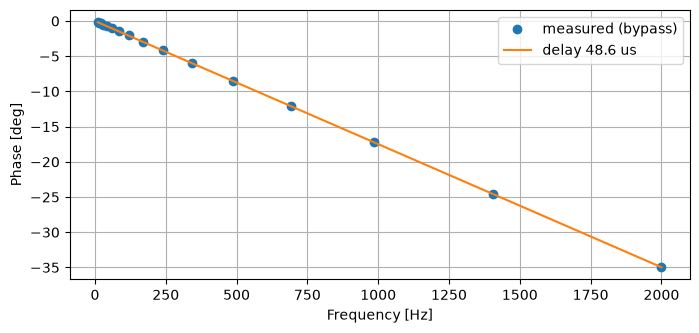

In [10]:
lab.mimic.bypass()
byp = lab.frequency_response(freqs, monitor=True)
slope = np.polyfit(byp.freq, byp.phase, 1)[0]   # deg per Hz
delay = -slope / 360
print(f"delay: {delay * 1e6:.1f} us")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(byp.freq, byp.phase, "o", label="measured (bypass)")
ax.plot(byp.freq, -360 * byp.freq * delay, "-", label=f"delay {delay * 1e6:.1f} us")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Phase [deg]")
ax.grid(True)
ax.legend()
plt.show()

位相は周波数に比例して遅れ、横軸を普通の目盛りにすると直線になります。遅れは約 50 µs です。内訳は次のとおりです。

| 原因 | 遅れ |
|---|---|
| Mimic の入力のフィルタ(折り返し雑音を防ぐ) | 約 16 µs |
| Mimic の計算(入力を読んでから出力するまで) | 約 16 µs |
| 信号発生器の**階段**:DAC は 50 µs ごとに値を書き換えるので、なめらかな信号より平均で半分(25 µs)遅れる。CH1 は書き換えた直後に読むので、この遅れは CH1 には現れず、Mimic の出力にだけ現れる | 約 25 µs |
| CH1 と CH2 を読む時刻のずれ(CH2 があと) | 約 −6 µs |

この遅れを理論に入れて($H \times e^{-j 2\pi f t_d}$)、実験 1 の LPF と比べ直します。

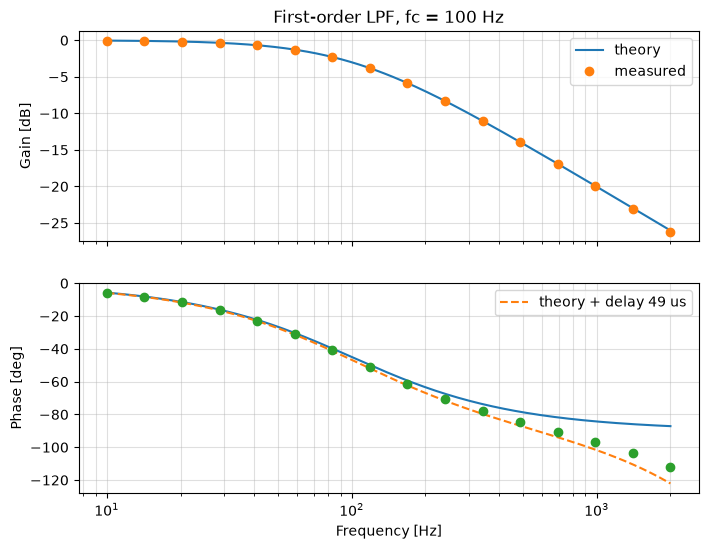

In [11]:
h = 1 / (1 + 1j * f_th / FC)
fig, ax1, ax2 = bode_axes(f"First-order LPF, fc = {FC} Hz")
ax1.semilogx(f_th, 20 * np.log10(abs(h)), "-", label="theory")
ax2.semilogx(f_th, np.degrees(np.angle(h)), "-")
ax2.semilogx(f_th, np.degrees(np.angle(h)) - 360 * f_th * delay, "--",
             label=f"theory + delay {delay * 1e6:.0f} us")
ax1.semilogx(lpf.freq, lpf.gain_db, "o", label="measured")
ax2.semilogx(lpf.freq, lpf.phase, "o")
ax1.legend()
ax2.legend()
plt.show()

遅れを入れた理論は、測った位相とよく合います。講義で扱う 100 Hz 前後では、この遅れによる位相のずれは 2° 程度です。

**測れる周波数の上限**:この遅れによる位相のずれは、5 kHz では 90° にもなります。また、取り込みは 20 kHz なので、5 kHz では 1 周期に 4 点しかなく、信号発生器も 50 µs ごとの階段なので正弦波の形がくずれます。そのため、この測定器で測るのは 2 kHz 程度までにしています。測定器の性能で、測れる範囲が決まります。

## まとめ

- ボード線図は、周波数ごとのゲイン [dB] と位相を、周波数の対数で描いたもの。正弦波の周波数を変えながら波形を取り込み、各周波数で振幅と位相を当てはめて求める(`frequency_response`)。
- 1 次の LPF / HPF のゲインの傾きは 20 dB/decade。
- 一定の遅れ $t_d$ は、周波数に比例した位相の遅れ($-360^\circ f t_d$)になる。この測定器と Mimic では、合わせて約 50 µs。

最後に接続を閉じます。

In [12]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()